# Bank Marketing Prediction: An End-to-End Machine Learning Classification Project

**Inovegen AI/ML Internship Program 2026 — Task 4: End-to-End Predictive Analytics (Final Project)**

## 1. Title, Objective, and Problem Definition

**Business problem.** A Portuguese bank ran direct-marketing campaigns, mostly by phone, to sell a **term deposit** (a savings product where money is locked for a fixed period). Calling every client is expensive and many clients say no. If the bank can estimate *which clients are more likely to subscribe*, it can prioritise its calls and spend its limited call-centre time more wisely.

**Prediction task.** Build a supervised machine-learning **binary classifier** that predicts whether a client subscribes to a term deposit.

- **Target variable:** `y` — `"yes"` (subscribed) or `"no"` (did not subscribe).
- **Inputs:** client information (age, job, balance, loans, ...) and information about the campaign contacts.

**Why it is useful.** A ranked or filtered call list lets the bank contact likely subscribers first, reduce wasted calls, and reduce annoyance for clients who are unlikely to be interested.

**Important caveat.** The model learns *predictive relationships*, not *causes*. If the model finds that a feature is associated with subscription, that does not mean changing that feature would cause a client to subscribe.

**Dataset.** UCI Machine Learning Repository — *Bank Marketing* (file `bank-full.csv`). Full citation, licence and download instructions are in Section 3.

## 2. Imports and Reproducibility

Only libraries that are actually used are imported. A single `RANDOM_STATE` is used everywhere (data split, models, permutation importance) so that results can be reproduced when the notebook is run again.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

## 3. Load the Dataset

**Source and citation**

- **Dataset:** Bank Marketing, UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/222/bank+marketing
- **Citation:** Moro, S., Rita, P., & Cortez, P. *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
- **Related paper:** Moro, S., Cortez, P., & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31.
- **Licence:** Creative Commons Attribution 4.0 (CC BY 4.0), as stated on the UCI page.
- **File used:** `bank-full.csv` — all 45,211 examples with 17 input columns. According to the UCI page this is the *older version* of the dataset (the newer `bank-additional` files have 20 inputs).
- **Target definition:** `y` = has the client subscribed to a term deposit? (`yes` / `no`).

**Known data limitations (from the UCI description and the data itself):** the campaigns belong to one Portuguese bank and are historical (the data is ordered by date and relates to roughly 2008–2010), so the clients may not represent other banks, countries or today's customers.

**How to get the file (needed once)**

1. Open https://archive.ics.uci.edu/dataset/222/bank+marketing and click **Download**.
2. Unzip the downloaded archive; inside it, `bank.zip` contains `bank-full.csv` (and `bank.csv`, a 10% sample — do **not** use that one).
3. **Google Colab:** run the next cell and, when asked, choose `bank-full.csv` from your computer. **Jupyter / local:** put `bank-full.csv` in the same folder as this notebook.

The file uses **semicolons (`;`)** as separators, so `sep=";"` is required.

In [2]:
DATA_PATH = "bank-full.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files  # only available inside Google Colab
        print("bank-full.csv not found - please upload it now.")
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            "bank-full.csv not found. Download it from the UCI link above and place it "
            "in the same folder as this notebook."
        )

df = pd.read_csv(DATA_PATH, sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Shape (rows, columns): (45211, 17)

Column names: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


**Column meaning (from the UCI documentation).** Client data: `age`, `job`, `marital`, `education`, `default` (credit in default?), `balance` (average yearly balance in euros), `housing` (housing loan?), `loan` (personal loan?). Last-contact data: `contact` (communication type), `day`, `month`, `duration` (last call length in seconds). Campaign data: `campaign` (contacts made to this client in this campaign), `pdays` (days since the client was last contacted in a previous campaign, `-1` = never), `previous` (contacts before this campaign), `poutcome` (outcome of the previous campaign). Target: `y`.

## 4. Data Inspection and Cleaning

We inspect the data *before* changing anything, so every cleaning decision is backed by evidence.

In [4]:
# Missing values and duplicates BEFORE cleaning
missing_before = int(df.isnull().sum().sum())
duplicates_before = int(df.duplicated().sum())
rows_before = len(df)
sentinel_before = int((df["pdays"] == -1).sum())

print("Total missing values (NaN):", missing_before)
print("Duplicate rows:", duplicates_before)
print("Rows:", rows_before)

Total missing values (NaN): 0
Duplicate rows: 0
Rows: 45211


In [5]:
# Unique values of every categorical column
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

for col in categorical_columns:
    print(f"{col}: {sorted(df[col].unique().tolist())}")

job: ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
marital: ['divorced', 'married', 'single']
education: ['primary', 'secondary', 'tertiary', 'unknown']
default: ['no', 'yes']
housing: ['no', 'yes']
loan: ['no', 'yes']
contact: ['cellular', 'telephone', 'unknown']
month: ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
poutcome: ['failure', 'other', 'success', 'unknown']
y: ['no', 'yes']


In [6]:
# 'unknown' is used as a category in several columns - how common is it?
unknown_counts = (df[categorical_columns] == "unknown").sum()
unknown_counts[unknown_counts > 0].to_frame("count of 'unknown'").assign(
    percent=lambda t: (t["count of 'unknown'"] / len(df) * 100).round(2)
)

,count of 'unknown',percent
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
# Checks for unusual values
print("Rows with pdays == -1 (never contacted before):", (df["pdays"] == -1).sum(),
      f"({(df['pdays'] == -1).mean():.1%})")
print("Rows with previous == 0:", (df["previous"] == 0).sum())
print("Rows with pdays == -1 but previous > 0 (inconsistent):",
      ((df["pdays"] == -1) & (df["previous"] > 0)).sum())
print("Smallest pdays among previously-contacted clients:", df.loc[df["pdays"] != -1, "pdays"].min())
print("\nRows with negative balance:", (df["balance"] < 0).sum())
print("Largest balance:", df["balance"].max(), "| smallest balance:", df["balance"].min())
print("Rows with duration == 0:", (df["duration"] == 0).sum())

Rows with pdays == -1 (never contacted before): 36954 (81.7%)
Rows with previous == 0: 36954
Rows with pdays == -1 but previous > 0 (inconsistent): 0
Smallest pdays among previously-contacted clients: 1

Rows with negative balance: 3766
Largest balance: 102127 | smallest balance: -8019
Rows with duration == 0: 3


### Findings and cleaning decisions

| Observation | Decision and reasoning |
|---|---|
| **No missing values (NaN) and no duplicate rows** | Nothing to impute or remove. No rows are deleted. (The imputers in the pipeline are kept as a safety net.) |
| **`unknown` appears in `job`, `education`, `contact`, `poutcome`** | `unknown` is *not* a NaN here; it is a recorded category. Deleting those rows would throw away a lot of data (for example, `contact = unknown` and `poutcome = unknown` are both very common), and "unknown" may itself carry information. We **keep it as its own category** and let the one-hot encoder handle it. |
| **`pdays = -1`** means "client was not contacted in a previous campaign" (about 82% of rows). It is a *code*, not a real number of days, and `-1` is mathematically misleading for models that treat `pdays` as a quantity (Logistic Regression would treat `-1` as "slightly less than 0 days"). The data is consistent: `pdays = -1` happens exactly when `previous = 0`, and real `pdays` values start at 1. | We create a clear binary feature **`previously_contacted`** (1/0) and then replace `-1` with `0` in `pdays`, so `pdays > 0` only for clients who really were contacted before. No rows are lost. |
| **Negative `balance` values** | These are plausible (overdrawn accounts), not errors. **Kept.** |
| **Very large `balance`, `campaign`, `previous` values (outliers)** | These are rare but plausible. They are kept; scaling is applied, and Random Forest is not sensitive to outliers. Charts that would be unreadable because of them hide extreme points (stated on each chart). |
| **`duration` equals 0 for a few rows** | Only a handful of rows; kept. `duration` as a whole is a special column handled in Section 6. |

In [9]:
# Cleaning step 1: remove duplicate rows only if there are any (there are none in this file)
if duplicates_before > 0:
    df = df.drop_duplicates().reset_index(drop=True)

# Cleaning step 2: make the 'pdays' sentinel value explicit
df["previously_contacted"] = (df["pdays"] != -1).astype(int)
df["pdays"] = df["pdays"].replace(-1, 0)

# Report before / after
print(f"{'':28s}{'before':>10s}{'after':>10s}")
print(f"{'rows':28s}{rows_before:>10d}{len(df):>10d}")
print(f"{'missing values (NaN)':28s}{missing_before:>10d}{int(df.isnull().sum().sum()):>10d}")
print(f"{'duplicate rows':28s}{duplicates_before:>10d}{int(df.duplicated().sum()):>10d}")
print(f"{'pdays == -1 rows':28s}{sentinel_before:>10d}{int((df['pdays'] == -1).sum()):>10d}")
print("\nNew column 'previously_contacted' counts:")
print(df["previously_contacted"].value_counts())

                                before     after
rows                             45211     45211
missing values (NaN)                 0         0


duplicate rows                       0         0
pdays == -1 rows                 36954         0

New column 'previously_contacted' counts:
previously_contacted
0    36954
1     8257
Name: count, dtype: int64


## 5. Exploratory Data Analysis (EDA)

**Counts vs. rates.** A bar of raw counts mostly shows which groups are *large*. To see which groups subscribe *more often*, we use the **subscription rate** (share of clients in that group who said `yes`). Category sizes (`n`) are shown in the axis labels so small groups are not over-interpreted. The dashed line on each rate chart is the **overall subscription rate**.

The small helper function below only prepares a table of rate and size for one column; it is used many times, which is why it is defined once.

In [10]:
overall_rate = (df["y"] == "yes").mean()
print(f"Overall subscription rate: {overall_rate:.2%}")

def subscription_rate(column, order=None):
    """Return a table with the subscription rate and group size for each category of `column`."""
    table = (df["y"] == "yes").groupby(df[column], observed=True).agg(rate="mean", n="size")
    if order is None:
        return table.sort_values("rate", ascending=True)
    return table.loc[order]

Overall subscription rate: 11.70%


### 5.1 Target distribution

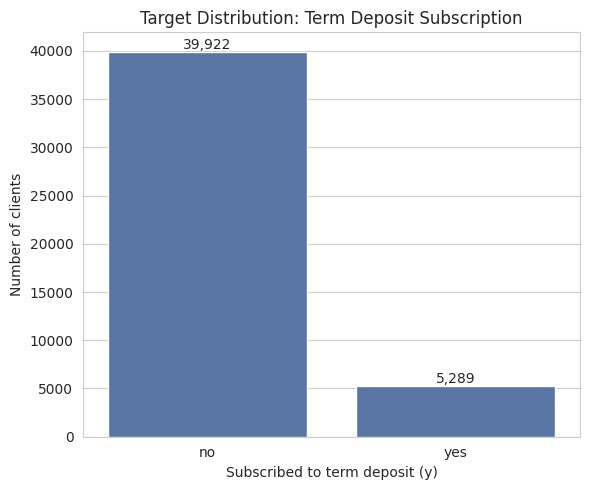

y
no     39922
yes     5289
Name: count, dtype: int64



y
no     0.883
yes    0.117
Name: proportion, dtype: float64


In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=df, x="y", order=["no", "yes"], color="#4c72b0", ax=ax)
ax.set_title("Target Distribution: Term Deposit Subscription")
ax.set_xlabel("Subscribed to term deposit (y)")
ax.set_ylabel("Number of clients")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
plt.tight_layout()
plt.show()

print(df["y"].value_counts())
print()
print(df["y"].value_counts(normalize=True).round(4))

**Observation.** The target is **strongly imbalanced**: 39,922 clients (88.3%) did not subscribe and 5,289 clients (11.7%) did. A model that always predicts "no" would already be about 88% accurate while finding *no* subscribers at all, so accuracy alone will be misleading (this is tested in Section 10).

### 5.2 Subscription rate by job and by education

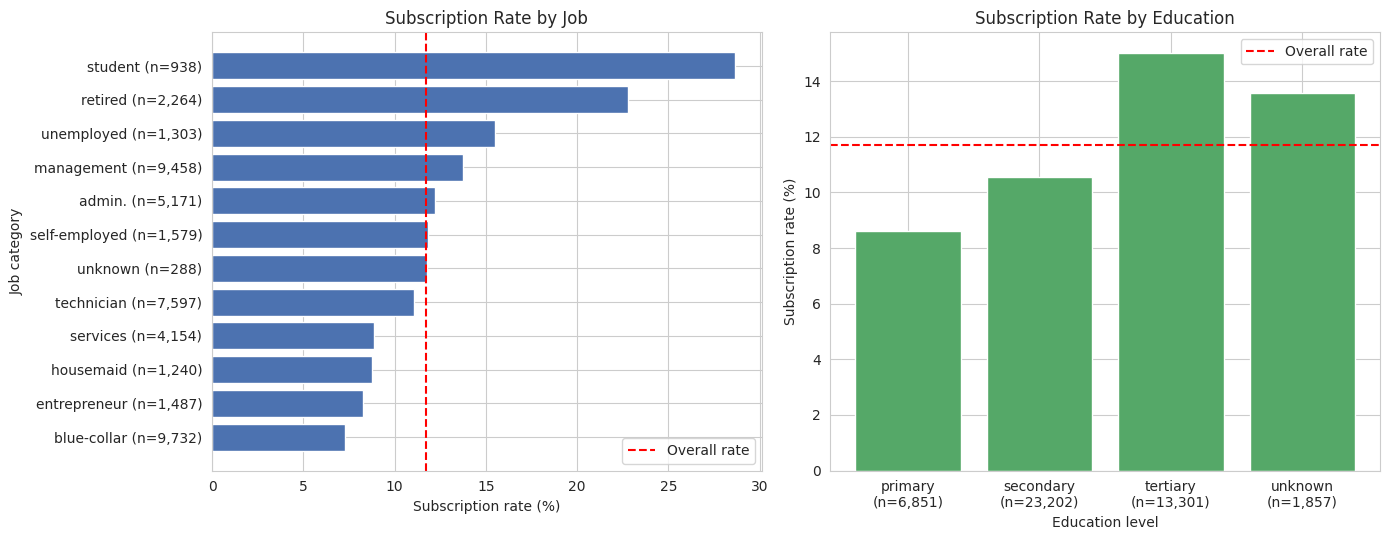

In [12]:
job_rates = subscription_rate("job")
edu_rates = subscription_rate("education", order=["primary", "secondary", "tertiary", "unknown"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].barh([f"{j} (n={n:,})" for j, n in zip(job_rates.index, job_rates["n"])],
             job_rates["rate"] * 100, color="#4c72b0")
axes[0].axvline(overall_rate * 100, color="red", linestyle="--", label="Overall rate")
axes[0].set_title("Subscription Rate by Job")
axes[0].set_xlabel("Subscription rate (%)")
axes[0].set_ylabel("Job category")
axes[0].legend()

axes[1].bar([f"{e}\n(n={n:,})" for e, n in zip(edu_rates.index, edu_rates["n"])],
            edu_rates["rate"] * 100, color="#55a868")
axes[1].axhline(overall_rate * 100, color="red", linestyle="--", label="Overall rate")
axes[1].set_title("Subscription Rate by Education")
axes[1].set_xlabel("Education level")
axes[1].set_ylabel("Subscription rate (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation.** Subscription rates differ clearly by job. **Students (28.7%)** and **retired** clients (22.8%) subscribed most often, while **blue-collar** (7.3%), **entrepreneur** (8.3%) and **housemaid** (8.8%) clients subscribed least often; the overall rate is 11.7%. By education, **tertiary** clients subscribed at 15.0% versus 8.6% for **primary** and 10.6% for **secondary**. Students and retired clients are smaller groups than blue-collar or management clients, so their rates are less certain, but the gaps are large. These are associations only: the data does not say *why* these groups differ.

### 5.3 Subscription rate by contact method and by month

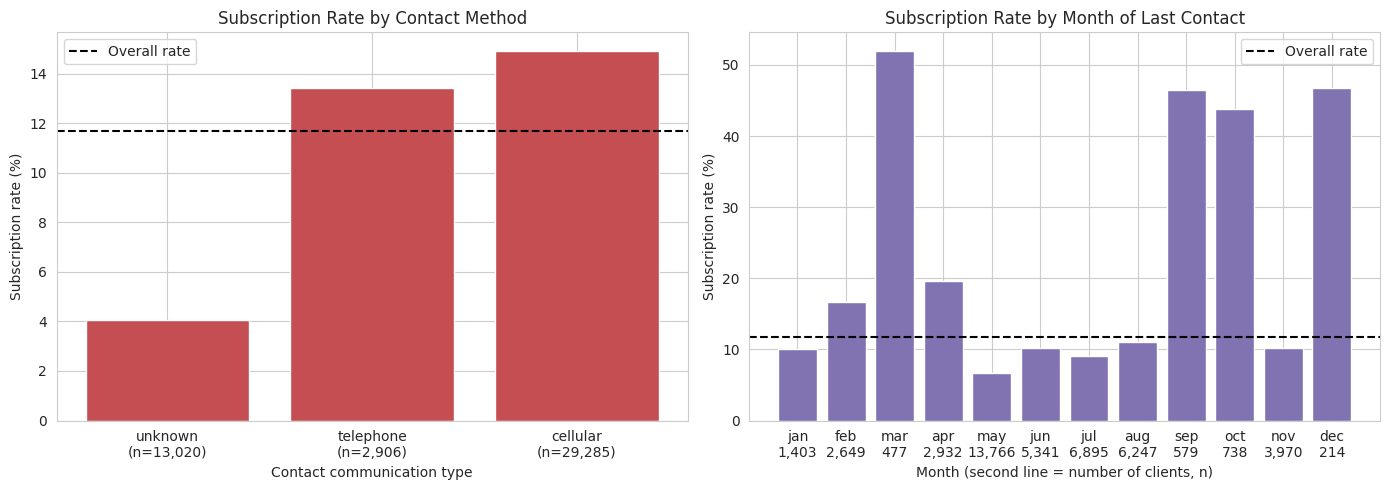

In [13]:
contact_rates = subscription_rate("contact")
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rates = subscription_rate("month", order=month_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar([f"{c}\n(n={n:,})" for c, n in zip(contact_rates.index, contact_rates["n"])],
            contact_rates["rate"] * 100, color="#c44e52")
axes[0].axhline(overall_rate * 100, color="black", linestyle="--", label="Overall rate")
axes[0].set_title("Subscription Rate by Contact Method")
axes[0].set_xlabel("Contact communication type")
axes[0].set_ylabel("Subscription rate (%)")
axes[0].legend()

axes[1].bar([f"{m}\n{n:,}" for m, n in zip(month_rates.index, month_rates["n"])],
            month_rates["rate"] * 100, color="#8172b2")
axes[1].axhline(overall_rate * 100, color="black", linestyle="--", label="Overall rate")
axes[1].set_title("Subscription Rate by Month of Last Contact")
axes[1].set_xlabel("Month (second line = number of clients, n)")
axes[1].set_ylabel("Subscription rate (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation.** Clients reached by **cellular** phone subscribed at 14.9% and by **telephone** at 13.4%, whereas clients whose contact type is **unknown** subscribed at only 4.1% (and this is a large group, 13,020 clients). By month, **May** is by far the busiest month (13,766 contacts) and has one of the *lowest* rates (6.7%). **March (52.0%)**, **September (46.5%)**, **October (43.8%)** and **December (46.7%)** have very high rates, but these months have very few contacts (214–738 clients), so those rates are based on small groups. Month therefore looks informative, but part of that pattern may reflect *how* and *to whom* the bank ran its campaigns in each month rather than anything about the month itself.

### 5.4 Subscription rate by previous-campaign outcome and by age group

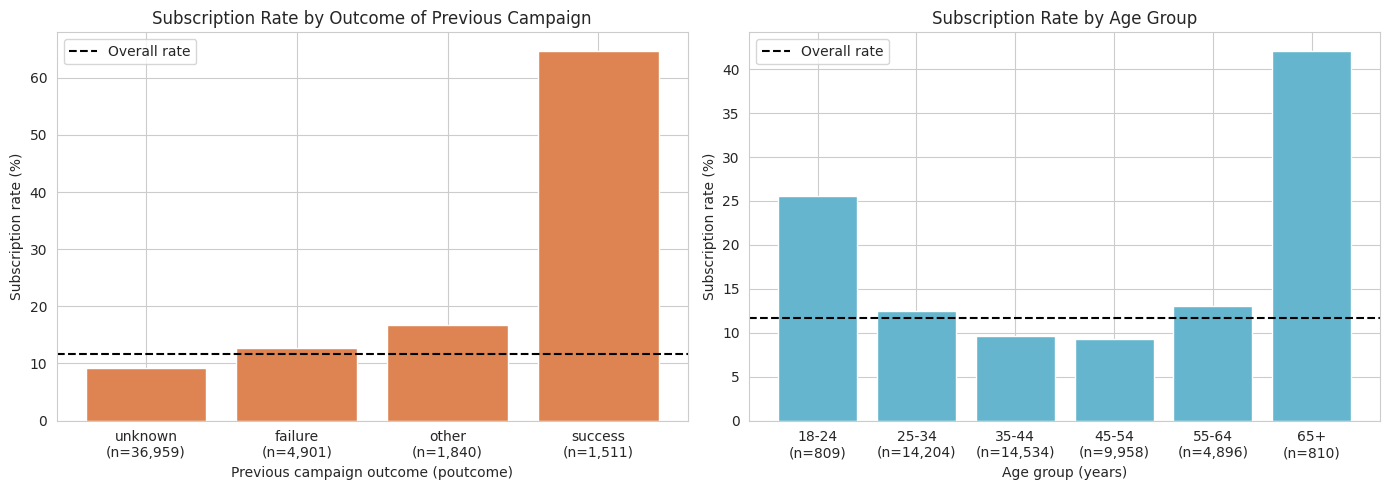

In [14]:
poutcome_rates = subscription_rate("poutcome")

df["age_group"] = pd.cut(df["age"], bins=[17, 24, 34, 44, 54, 64, 100],
                         labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])
age_rates = subscription_rate("age_group", order=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar([f"{p}\n(n={n:,})" for p, n in zip(poutcome_rates.index, poutcome_rates["n"])],
            poutcome_rates["rate"] * 100, color="#dd8452")
axes[0].axhline(overall_rate * 100, color="black", linestyle="--", label="Overall rate")
axes[0].set_title("Subscription Rate by Outcome of Previous Campaign")
axes[0].set_xlabel("Previous campaign outcome (poutcome)")
axes[0].set_ylabel("Subscription rate (%)")
axes[0].legend()

axes[1].bar([f"{a}\n(n={n:,})" for a, n in zip(age_rates.index, age_rates["n"])],
            age_rates["rate"] * 100, color="#64b5cd")
axes[1].axhline(overall_rate * 100, color="black", linestyle="--", label="Overall rate")
axes[1].set_title("Subscription Rate by Age Group")
axes[1].set_xlabel("Age group (years)")
axes[1].set_ylabel("Subscription rate (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation.** Clients whose **previous campaign succeeded** subscribed at **64.7%**, compared with 12.6% after a previous failure and 9.2% when the previous outcome is unknown, so past success is strongly associated with subscribing again (this group has 1,511 clients). By age, the relationship is **U-shaped**: the youngest group (18–24, 25.6%) and especially the oldest group (65+, 42.1%) subscribe far more often than middle-aged clients (35–54, about 9–10%). The 18–24 and 65+ groups are small (about 810 clients each), which is worth remembering.

### 5.5 Numerical variables vs. subscription

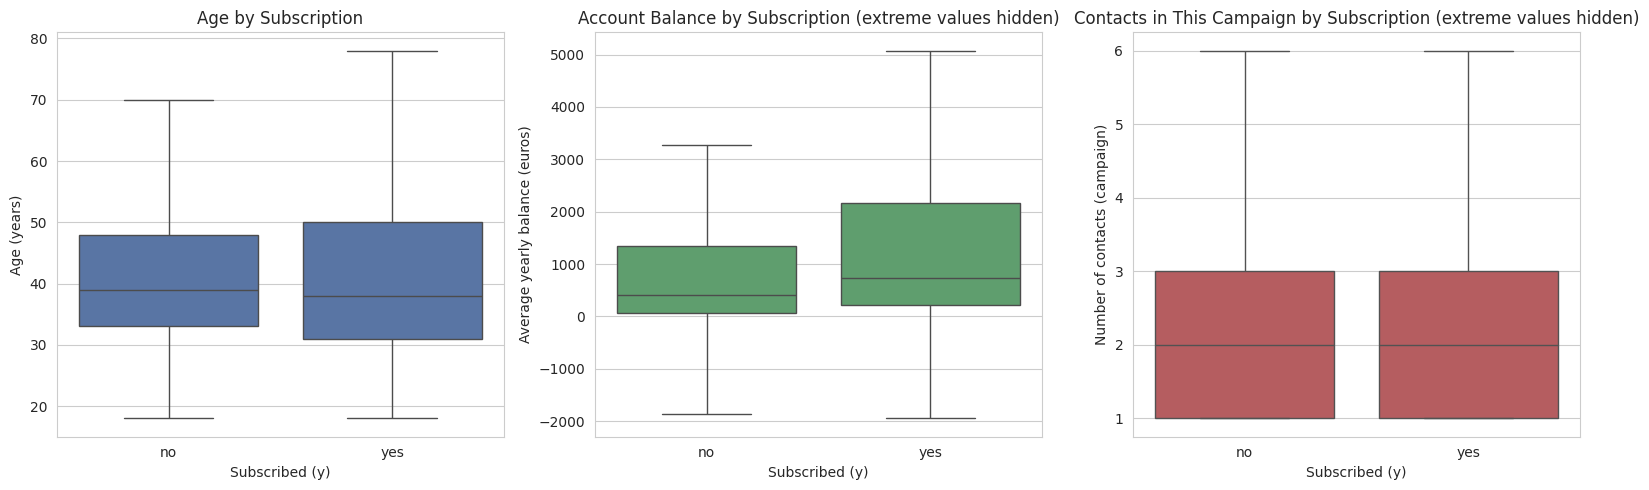

      age  balance  campaign
y                           
no   39.0    417.0       2.0
yes  38.0    733.0       2.0

Subscription rate by number of contacts in this campaign (10 = 10 or more):
campaign
1     0.146
2     0.112
3     0.112
4     0.090
5     0.079
6     0.071
7     0.064
8     0.059
9     0.064
10    0.042
Name: y, dtype: float64


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# showfliers=False hides extreme points so the boxes stay readable
sns.boxplot(data=df, x="y", y="age", order=["no", "yes"], color="#4c72b0", showfliers=False, ax=axes[0])
axes[0].set_title("Age by Subscription")
axes[0].set_xlabel("Subscribed (y)")
axes[0].set_ylabel("Age (years)")

sns.boxplot(data=df, x="y", y="balance", order=["no", "yes"], color="#55a868", showfliers=False, ax=axes[1])
axes[1].set_title("Account Balance by Subscription (extreme values hidden)")
axes[1].set_xlabel("Subscribed (y)")
axes[1].set_ylabel("Average yearly balance (euros)")

sns.boxplot(data=df, x="y", y="campaign", order=["no", "yes"], color="#c44e52", showfliers=False, ax=axes[2])
axes[2].set_title("Contacts in This Campaign by Subscription (extreme values hidden)")
axes[2].set_xlabel("Subscribed (y)")
axes[2].set_ylabel("Number of contacts (campaign)")

plt.tight_layout()
plt.show()

print(df.groupby("y")[["age", "balance", "campaign"]].median())

print("\nSubscription rate by number of contacts in this campaign (10 = 10 or more):")
print((df["y"] == "yes").groupby(df["campaign"].clip(upper=10)).mean().round(3))

**Observation.** The median **age** is almost the same for both groups (39 for "no", 38 for "yes"), which fits the U-shaped pattern above: age matters in the extremes rather than as a straight line. The median **balance** is higher for subscribers (733 euros) than for non-subscribers (417 euros). **Campaign** (number of contacts) has the same median (2) in both groups, but its *mean* is lower for subscribers (2.14 vs. 2.85), and the rate table printed under the chart shows the subscription rate falling from 14.6% for clients contacted once to 4.2% for clients contacted 10 or more times. None of these numerical differences is large on its own; a model can combine many small signals.

## 6. Feature Engineering and Selection

### 6.1 Separate features (X) from the target (y)
`X` holds the inputs the model may use; `y` is the answer it must predict. The target `y` is text (`yes`/`no`), so it is converted to `1`/`0` where **1 = subscribed** (the "positive" class that the bank cares about).

### 6.2 The special case of `duration`
`duration` is the length of the **last phone call in seconds**. It is very tempting because it is strongly related to the outcome — but it is a problem for a realistic system:

- The bank wants to decide **before** calling whom to call. The call length is **not known until the call has happened**.
- By the time the call has ended, the outcome (`y`) is essentially already known, so using `duration` is a form of **target leakage**: the feature contains information that would not be available at prediction time. The UCI documentation itself warns that `duration` should only be used for benchmark purposes if a realistic predictive model is wanted.
- Calls that never connect last 0 seconds, which almost guarantees `y = "no"`.

The two cells below show how strongly `duration` is linked to the target.

Median call duration (seconds) by outcome:
y
no     164.0
yes    426.0
Name: duration, dtype: float64


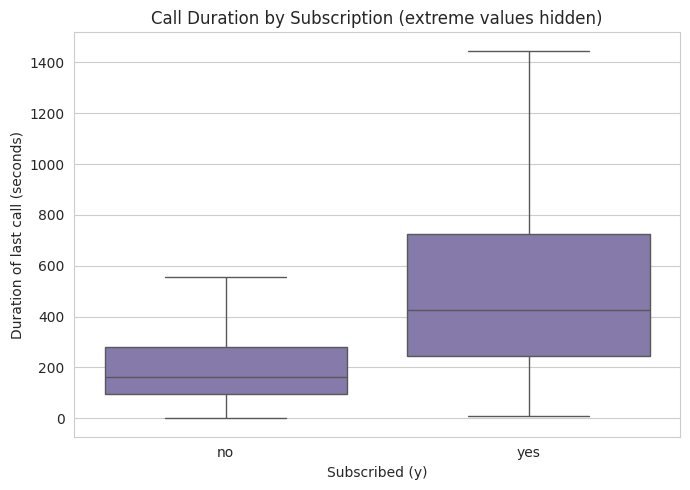

In [16]:
print("Median call duration (seconds) by outcome:")
print(df.groupby("y")["duration"].median())

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="y", y="duration", order=["no", "yes"], color="#8172b2", showfliers=False, ax=ax)
ax.set_title("Call Duration by Subscription (extreme values hidden)")
ax.set_xlabel("Subscribed (y)")
ax.set_ylabel("Duration of last call (seconds)")
plt.tight_layout()
plt.show()

**Decision.** Subscribers' calls were much longer (median 426 s vs. 164 s). That is exactly why `duration` is **excluded from the primary model**: the primary model is meant to simulate a *pre-contact* decision. In Section 11 a clearly labelled **secondary experiment** includes `duration` just to show how much it would inflate the results, and why that model is *not* realistic.

### 6.3 Other columns
- `default`, `housing`, `loan`, `marital`, `education`, `job`, `balance`, `contact`, `day`, `month`, `campaign`, `pdays`, `previous`, `poutcome` and the new `previously_contacted` are **kept** — they are known before the call or are part of the client's history, and there is no defensible reason to remove them.
- `age_group` was created only for the EDA chart (it duplicates `age`), so it is **dropped** to avoid redundant information.
- No identifier columns exist in this dataset.

In [17]:
target_column = "y"
leakage_columns = ["duration"]            # excluded from the primary model (see 6.2)
helper_columns = ["age_group"]            # EDA helper only

y = (df[target_column] == "yes").astype(int)          # 1 = subscribed, 0 = not subscribed
X = df.drop(columns=[target_column] + leakage_columns + helper_columns)

# Identify numerical and categorical columns programmatically
numerical_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Number of features:", X.shape[1])
print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nTarget in X?", target_column in X.columns, "| duration in X?", "duration" in X.columns)

Number of features: 16

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target in X? False | duration in X? False


## 7. Preprocessing Pipeline

Models need numbers, and different column types need different treatment:

- **Numerical features:** median imputation (a safety net — there are no missing values now, but it protects the pipeline if new data has gaps) followed by `StandardScaler`, which puts features on a comparable scale. Scaling matters for Logistic Regression; Random Forest does not need it, but it does no harm.
- **Categorical features:** most-frequent imputation (safety net) followed by `OneHotEncoder(handle_unknown="ignore")`, which turns each category into its own 0/1 column. `handle_unknown="ignore"` prevents an error if a category appears only in the test data.

A `ColumnTransformer` applies each recipe to the right columns, and a `Pipeline` chains preprocessing and model. Because everything is inside a pipeline, **calling `.fit()` learns the medians, scaling values and categories from the training data only**, and then merely *applies* them to the test data. This prevents **data leakage** from the test set.

The small function below builds this preprocessor; it is a function only because it is needed again for the secondary `duration` experiment (which has a different list of numerical columns).

In [18]:
def make_preprocessor(numerical_cols, categorical_cols):
    numerical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ])

preprocessor = make_preprocessor(numerical_features, categorical_features)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 8. Train/Test Split

- **80% training / 20% testing**, with `random_state=42` so the split is the same on every run.
- **Stratified** (`stratify=y`): because only about 12% of clients subscribe, a purely random split could give the training and test sets different proportions. Stratification keeps the class proportions the same in both.
- The **test set is used only for final evaluation** — it is not used to choose or tune parameters.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples: ", len(X_test))
print("\nClass proportions (share of 'yes'):")
print(f"  full data : {y.mean():.4f}")
print(f"  train set : {y_train.mean():.4f}")
print(f"  test set  : {y_test.mean():.4f}")

Training samples: 36168
Testing samples:  9043

Class proportions (share of 'yes'):
  full data : 0.1170
  train set : 0.1170
  test set  : 0.1170


## 9. Train and Compare Models

All models use the **same split, the same preprocessing and the same evaluation steps**, so the comparison is fair.

**Baseline (reference only): `DummyClassifier`** always predicts the majority class ("no"). It shows what "accuracy" looks like when the model has learned nothing.

**Model A — Logistic Regression.** A linear model that estimates the probability of subscription from a weighted sum of the features. It is fast and easy to interpret. `max_iter=1000` gives it enough iterations to converge.

**Model B — Random Forest.** Many decision trees, each trained on a random sample of rows and features, vote on the answer. It can capture non-linear patterns and interactions between features, but is harder to interpret. `n_estimators=200` trees and `min_samples_leaf=5` (each leaf must contain at least 5 clients, which keeps the trees from memorising individual clients) are sensible starting settings; **no hyperparameter search was performed.**

**Handling class imbalance (justified choice).** Only ~11.7% of clients subscribe. With the default settings, a model is rewarded for mostly predicting "no", so it finds few real subscribers. For a bank deciding whom to call, *missing a likely subscriber is generally a more costly error than making one extra call*, so both models use **class weights** (`class_weight="balanced"` for Logistic Regression, `"balanced_subsample"` for Random Forest), which make mistakes on the minority "yes" class count more during training. This was chosen *before* looking at test results because of the imbalance and the business goal. As a **clearly labelled reference**, we also train Logistic Regression *without* class weights to show the effect of this decision.

**Decision threshold.** Each model outputs a probability of subscribing. `predict()` converts it to a class using a **fixed threshold of 0.5**: probability ≥ 0.5 → predict "yes". Threshold tuning is listed as a future improvement and is not done here.

In [20]:
baseline = Pipeline([
    ("preprocessor", make_preprocessor(numerical_features, categorical_features)),
    ("model", DummyClassifier(strategy="most_frequent")),
])

logreg_reference = Pipeline([
    ("preprocessor", make_preprocessor(numerical_features, categorical_features)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

model_a = Pipeline([
    ("preprocessor", make_preprocessor(numerical_features, categorical_features)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

model_b = Pipeline([
    ("preprocessor", make_preprocessor(numerical_features, categorical_features)),
    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                     class_weight="balanced_subsample",
                                     random_state=RANDOM_STATE, n_jobs=-1)),
])

baseline.fit(X_train, y_train)
logreg_reference.fit(X_train, y_train)
model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)
print("All models trained on", len(X_train), "training samples.")

All models trained on 36168 training samples.


## 10. Evaluate Model Performance

**Metrics (the "positive" class is *subscribed*):**

- **Accuracy** — share of all predictions that are correct. Misleading when one class dominates.
- **Precision** — of the clients the model predicted *would subscribe*, how many actually did? (Low precision = many wasted calls.)
- **Recall** — of the clients who *actually subscribed*, how many did the model find? (Low recall = missed opportunities.)
- **F1-score** — a single number that balances precision and recall.
- **ROC-AUC** — how well the predicted *probabilities* rank subscribers above non-subscribers, regardless of any threshold (1.0 = perfect, 0.5 = random).

**Confusion matrix cells:** *True Positive* = predicted yes, actually yes; *True Negative* = predicted no, actually no; *False Positive* = predicted yes, actually no (a wasted call); *False Negative* = predicted no, actually yes (a missed subscriber).

The helper function below calculates all metrics the same way for every model so the comparison is consistent.

In [21]:
def evaluate_model(name, fitted_pipeline, X_eval, y_eval):
    y_pred = fitted_pipeline.predict(X_eval)                # uses the fixed 0.5 threshold
    y_prob = fitted_pipeline.predict_proba(X_eval)[:, 1]    # probability of class 1 (subscribed)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred),
        "F1-score": f1_score(y_eval, y_pred),
        "ROC-AUC": roc_auc_score(y_eval, y_prob),
    }

results = pd.DataFrame([
    evaluate_model("Baseline: always predict 'no'", baseline, X_test, y_test),
    evaluate_model("Reference: Logistic Regression (no class weights)", logreg_reference, X_test, y_test),
    evaluate_model("Model A: Logistic Regression (balanced)", model_a, X_test, y_test),
    evaluate_model("Model B: Random Forest (balanced)", model_b, X_test, y_test),
]).set_index("Model")

results.round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Baseline: always predict 'no',0.883,0.000,0.000,0.000,0.500
Reference: Logistic Regression (no class weights),0.893,0.664,0.180,0.283,0.772
Model A: Logistic Regression (balanced),0.756,0.267,0.624,0.374,0.772
Model B: Random Forest (balanced),0.866,0.441,0.536,0.484,0.803


**Accuracy can be misleading.** The baseline that never finds a single subscriber still scores about 88% accuracy, because 88% of clients say "no". Notice also that the unweighted Logistic Regression has *higher accuracy* than Model A, yet it finds far fewer subscribers (much lower recall). Accuracy alone would therefore pick the wrong model for a bank whose goal is to find subscribers. Precision, recall, F1 and ROC-AUC give the fuller picture.

### Classification reports

In [22]:
for name, fitted in [("Model A: Logistic Regression (balanced)", model_a),
                     ("Model B: Random Forest (balanced)", model_b)]:
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, fitted.predict(X_test), target_names=["No (0)", "Yes (1)"]))

Model A: Logistic Regression (balanced)
              precision    recall  f1-score   support

      No (0)       0.94      0.77      0.85      7985
     Yes (1)       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043

Model B: Random Forest (balanced)


              precision    recall  f1-score   support

      No (0)       0.94      0.91      0.92      7985
     Yes (1)       0.44      0.54      0.48      1058

    accuracy                           0.87      9043
   macro avg       0.69      0.72      0.70      9043
weighted avg       0.88      0.87      0.87      9043



### Confusion matrices

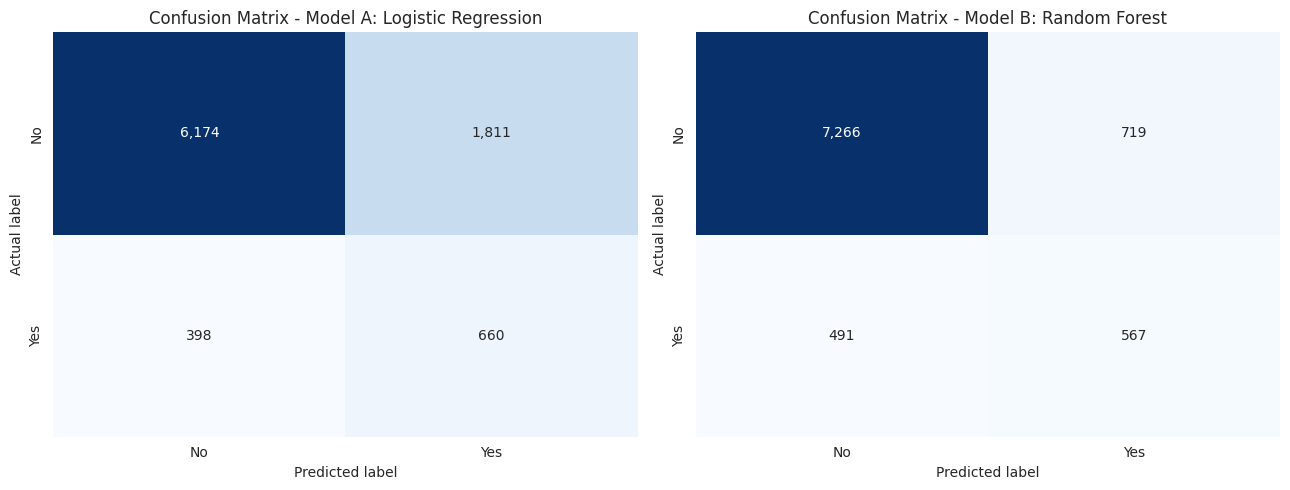

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, fitted in zip(axes,
                            ["Model A: Logistic Regression", "Model B: Random Forest"],
                            [model_a, model_b]):
    cm = confusion_matrix(y_test, fitted.predict(X_test))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

In [24]:
for name, fitted in [("Model A (Logistic Regression)", model_a), ("Model B (Random Forest)", model_b)]:
    tn, fp, fn, tp = confusion_matrix(y_test, fitted.predict(X_test)).ravel()
    print(f"{name}: TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")
    print(f"   -> found {tp:,} of {tp + fn:,} actual subscribers, "
          f"made {fp:,} calls to clients who would not subscribe\n")

Model A (Logistic Regression): TN=6,174  FP=1,811  FN=398  TP=660
   -> found 660 of 1,058 actual subscribers, made 1,811 calls to clients who would not subscribe



Model B (Random Forest): TN=7,266  FP=719  FN=491  TP=567
   -> found 567 of 1,058 actual subscribers, made 719 calls to clients who would not subscribe



**How to read this.** *True positives* are subscribers the model found; *false negatives* are subscribers it missed; *false positives* are calls that would be wasted on non-subscribers; *true negatives* are non-subscribers correctly left alone. Both models trade precision for recall because of the class weights: they flag many more clients as likely subscribers than the unweighted model does, which finds more real subscribers but also produces more false positives.

### Model comparison charts

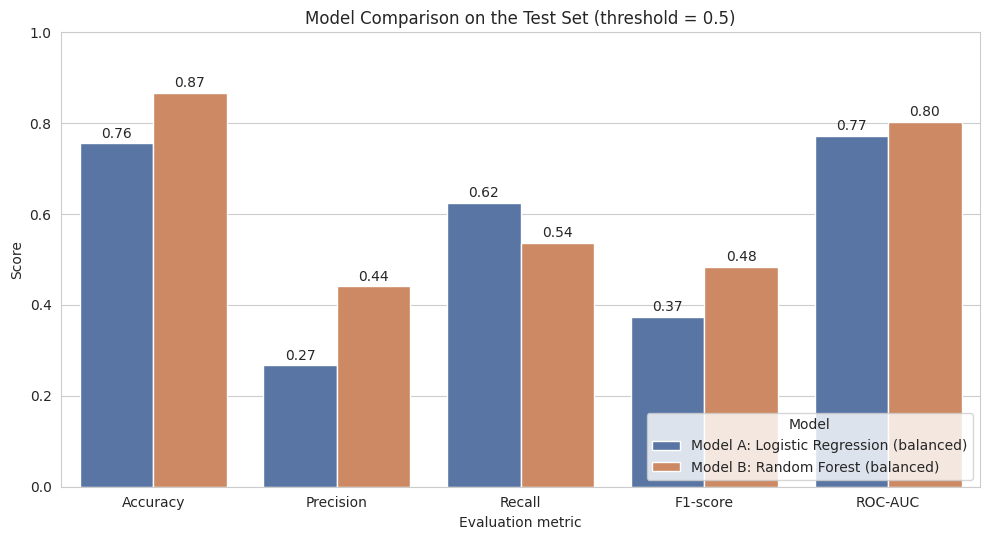

In [25]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_data = (results.loc[["Model A: Logistic Regression (balanced)", "Model B: Random Forest (balanced)"],
                         metrics_to_plot]
             .reset_index()
             .melt(id_vars="Model", var_name="Metric", value_name="Score"))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="Metric", y="Score", hue="Model", palette=["#4c72b0", "#dd8452"], ax=ax)
ax.set_title("Model Comparison on the Test Set (threshold = 0.5)")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

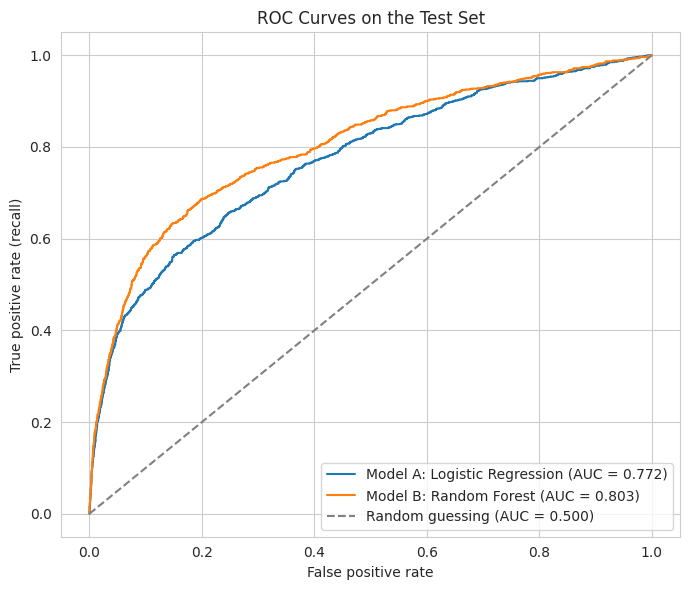

In [26]:
prob_a = model_a.predict_proba(X_test)[:, 1]
prob_b = model_b.predict_proba(X_test)[:, 1]
fpr_a, tpr_a, _ = roc_curve(y_test, prob_a)
fpr_b, tpr_b, _ = roc_curve(y_test, prob_b)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_a, tpr_a, label=f"Model A: Logistic Regression (AUC = {roc_auc_score(y_test, prob_a):.3f})")
ax.plot(fpr_b, tpr_b, label=f"Model B: Random Forest (AUC = {roc_auc_score(y_test, prob_b):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing (AUC = 0.500)")
ax.set_title("ROC Curves on the Test Set")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Model Comparison and Final Selection

The selection is based on several metrics, not accuracy alone. The cell below prints a summary computed directly from the results table.

In [27]:
a = results.loc["Model A: Logistic Regression (balanced)"]
b = results.loc["Model B: Random Forest (balanced)"]

comparison = pd.DataFrame({
    "Model A (LogReg)": a,
    "Model B (RandomForest)": b,
    "Better model": [("A" if a[m] > b[m] else "B") for m in results.columns],
})
comparison.round(3)

,Model A (LogReg),Model B (RandomForest),Better model
Accuracy,0.756,0.866,B
Precision,0.267,0.441,B
Recall,0.624,0.536,A
F1-score,0.374,0.484,B
ROC-AUC,0.772,0.803,B


### Final selection (plain-language reasoning)

Based on the results table above:

- **Random Forest (Model B)** has the higher **F1-score**, higher **precision** and higher **ROC-AUC**, and also higher accuracy. It ranks clients better and gives a better balance between wasted calls and found subscribers.
- **Logistic Regression (Model A)** has the higher **recall**: it catches a somewhat larger share of the actual subscribers, but at the price of much lower precision, i.e. many more wasted calls.
- This is a real **trade-off**, not a case where one model wins on everything. If the bank valued *finding every possible subscriber* above everything else and calls were almost free, Logistic Regression's higher recall would be attractive. Because calls have a cost and a ranked list of likely clients is the goal, the better balance (F1) and better ranking quality (ROC-AUC) matter more.

**Selected model: Random Forest (Model B).** The reasons are its higher F1 and ROC-AUC. The cost is that it is more complex and less transparent than Logistic Regression; permutation importance (Section 12) is used to partly open the "black box". The conclusion applies to *this dataset and this single test split* — the differences should be re-checked with cross-validation before any real use.

### Secondary experiment: what happens if `duration` is included? (NOT a realistic model)

To show why `duration` was excluded, we train the same two models **with** `duration`. This model uses information that is only known *after* the call, so its scores must not be treated as a realistic pre-contact system.

In [28]:
# SECONDARY EXPERIMENT - uses 'duration', which is NOT available before a call is made
X_dur = df.drop(columns=[target_column] + helper_columns)      # same as X, but WITH duration
numerical_dur = X_dur.select_dtypes(include="number").columns.tolist()
categorical_dur = X_dur.select_dtypes(exclude="number").columns.tolist()

# Same random_state and stratification -> the same clients end up in the same train/test sets
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_dur, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
assert (y_test_d.index == y_test.index).all()    # confirms the test clients are identical

model_a_dur = Pipeline([
    ("preprocessor", make_preprocessor(numerical_dur, categorical_dur)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
]).fit(X_train_d, y_train_d)

model_b_dur = Pipeline([
    ("preprocessor", make_preprocessor(numerical_dur, categorical_dur)),
    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                     class_weight="balanced_subsample",
                                     random_state=RANDOM_STATE, n_jobs=-1)),
]).fit(X_train_d, y_train_d)

duration_results = pd.DataFrame([
    evaluate_model("Model A (LogReg) - WITHOUT duration [primary]", model_a, X_test, y_test),
    evaluate_model("Model A (LogReg) - WITH duration [not realistic]", model_a_dur, X_test_d, y_test_d),
    evaluate_model("Model B (RandomForest) - WITHOUT duration [primary]", model_b, X_test, y_test),
    evaluate_model("Model B (RandomForest) - WITH duration [not realistic]", model_b_dur, X_test_d, y_test_d),
]).set_index("Model")

duration_results.round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Model A (LogReg) - WITHOUT duration [primary],0.756,0.267,0.624,0.374,0.772
Model A (LogReg) - WITH duration [not realistic],0.846,0.418,0.814,0.552,0.908
Model B (RandomForest) - WITHOUT duration [primary],0.866,0.441,0.536,0.484,0.803
Model B (RandomForest) - WITH duration [not realistic],0.880,0.493,0.800,0.610,0.930


In [29]:
auc_gain_rf = duration_results.iloc[3]["ROC-AUC"] - duration_results.iloc[2]["ROC-AUC"]
f1_gain_rf = duration_results.iloc[3]["F1-score"] - duration_results.iloc[2]["F1-score"]
display(Markdown(
    f"**Effect of adding `duration` (Random Forest):** ROC-AUC changes by **{auc_gain_rf:+.3f}** "
    f"and F1-score by **{f1_gain_rf:+.3f}**. A jump this large comes from information that only exists "
    f"after the call, so it would not be available when the bank has to decide whom to call."
))

**Effect of adding `duration` (Random Forest):** ROC-AUC changes by **+0.127** and F1-score by **+0.126**. A jump this large comes from information that only exists after the call, so it would not be available when the bank has to decide whom to call.

## 12. Feature Importance and Interpretation

We use **permutation importance** on the **held-out test set** with the selected Random Forest pipeline. It shuffles one original column at a time and measures how much the model's ROC-AUC drops: a larger drop means the model relied more on that column. Because the shuffling is applied to the *original* columns before the pipeline's one-hot encoding, each bar is a whole feature (for example `month`), and no one-hot column names need to be decoded. We use 5 shuffles per feature (`n_repeats=5`) and the fixed random seed.

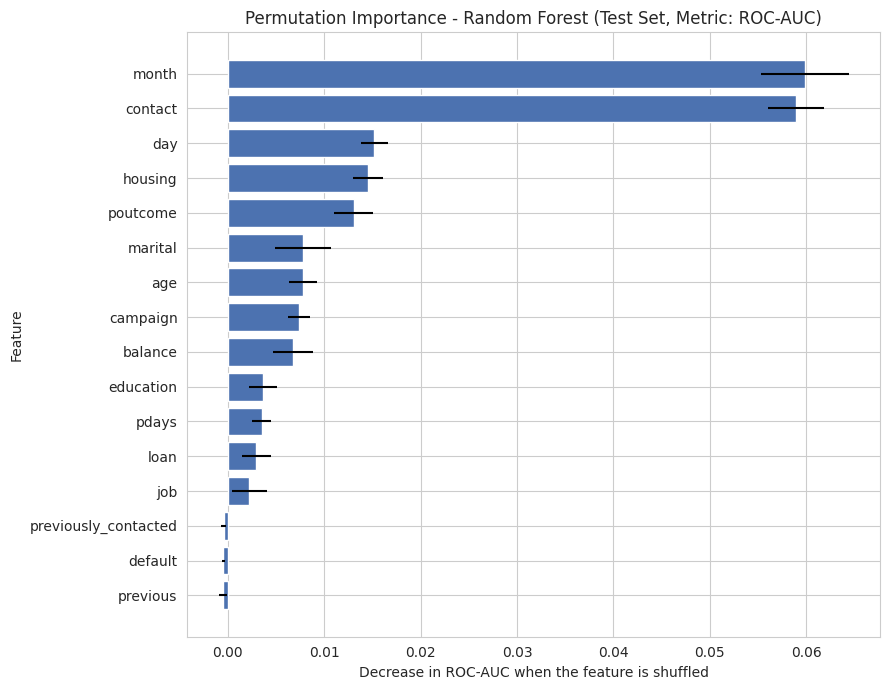

,feature,importance_mean,importance_std
10,month,0.0599,0.0045
8,contact,0.0589,0.0029
9,day,0.0152,0.0014
6,housing,0.0145,0.0016
14,poutcome,0.0131,0.0020
2,marital,0.0078,0.0029
0,age,0.0078,0.0015
11,campaign,0.0074,0.0011


In [30]:
perm = permutation_importance(
    model_b, X_test, y_test,
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)

importance_df = (pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=True))

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(importance_df["feature"], importance_df["importance_mean"],
        xerr=importance_df["importance_std"], color="#4c72b0")
ax.set_title("Permutation Importance - Random Forest (Test Set, Metric: ROC-AUC)")
ax.set_xlabel("Decrease in ROC-AUC when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

importance_df.sort_values("importance_mean", ascending=False).head(8).round(4)

In [31]:
top_features = importance_df.sort_values("importance_mean", ascending=False)["feature"].head(5).tolist()
display(Markdown(f"**Five most influential features in this run:** {', '.join(f'`{f}`' for f in top_features)}."))

**Five most influential features in this run:** `month`, `contact`, `day`, `housing`, `poutcome`.

**How to interpret this.**

- The longer the bar, the more the Random Forest's ranking quality (ROC-AUC) depends on that column; the thin error bars show how much the value moved between the five shuffles. In this run `month` and `contact` are far ahead of everything else (each lowers ROC-AUC by roughly 0.06 when shuffled), followed at a distance by `day`, `housing` and `poutcome` (roughly 0.013-0.015 each), and then `marital`, `age`, `campaign` and `balance` (below 0.01). Features such as `default`, `previous` and `previously_contacted` are about zero (tiny negative values are just noise), so the model does not rely on them.
- This agrees with part of the EDA: `contact` (cellular vs. unknown) and `month` showed very different subscription rates, and `poutcome` showed the biggest single difference of all. `housing` and `day` were not charted in the EDA, so their importance is a new observation from the model.
- A feature with strong EDA differences can still get a small importance, because information may overlap with other columns (for example, `poutcome`, `previous`, `pdays` and `previously_contacted` all describe the previous campaign, and `job`, `age`, `marital` and `balance` partly describe similar client groups). When columns share information, shuffling one of them hurts less, so permutation importance is a guide, not an exact ranking.
- **Importance is not causation.** A feature being important means the model uses it to *predict*; it does not mean that changing it would make a client subscribe. `month`, `day` and `contact` mostly describe *when and how* the bank ran its campaigns (and `contact = unknown` is likely a data-recording pattern), so they probably reflect how the campaigns were organised and to whom the calls were made, not a real effect of the calendar on a client's decision.

## 13. Key Findings

The findings below are generated from the notebook's actual results, so every number matches the outputs above.

In [32]:
n_total = len(df)
n_yes = int((df["y"] == "yes").sum())
best_model_name = "Random Forest (Model B)"

top3 = ", ".join(f"`{f}`" for f in top_features[:3])

display(Markdown(f"""
1. **Imbalanced target.** Only {n_yes:,} of {n_total:,} clients ({overall_rate:.1%}) subscribed to a term deposit, so a model that always says "no" is {results.loc["Baseline: always predict 'no'", "Accuracy"]:.1%} accurate but finds no subscribers. Accuracy alone is not a suitable metric here.
2. **EDA - who subscribes more.** Subscription rates were highest for students ({subscription_rate("job").loc["student", "rate"]:.1%}) and retired clients ({subscription_rate("job").loc["retired", "rate"]:.1%}), for clients whose previous campaign succeeded ({subscription_rate("poutcome").loc["success", "rate"]:.1%}), and for clients aged 65+ ({age_rates.loc["65+", "rate"]:.1%}); they were lowest for clients with an unknown contact type ({contact_rates.loc["unknown", "rate"]:.1%}) and in May ({month_rates.loc["may", "rate"]:.1%}). These are associations, not causes.
3. **Data preparation.** No missing values or duplicates were found, so no rows were deleted. `unknown` was kept as a category, the `pdays = -1` code was replaced by a `previously_contacted` flag, and `duration` was excluded from the primary model because it is only known after the call (leakage).
4. **Model comparison.** On the same 80/20 stratified split (test size {len(y_test):,}), Random Forest scored F1 = {b["F1-score"]:.3f} and ROC-AUC = {b["ROC-AUC"]:.3f}, versus F1 = {a["F1-score"]:.3f} and ROC-AUC = {a["ROC-AUC"]:.3f} for Logistic Regression. Logistic Regression had the higher recall ({a["Recall"]:.3f} vs. {b["Recall"]:.3f}) but lower precision ({a["Precision"]:.3f} vs. {b["Precision"]:.3f}).
5. **Selected model.** {best_model_name} was selected because of its better F1-score and ROC-AUC (a better balance of found subscribers and wasted calls), while acknowledging that Logistic Regression catches more subscribers at the price of many more false positives.
6. **Important predictors.** Permutation importance ranks {top3} as the most influential features for the selected model. Importance describes what the model relies on, not what causes subscription.
7. **Business implication.** At a 0.5 threshold the selected model flags clients likely to subscribe with a precision of {b["Precision"]:.1%} and finds {b["Recall"]:.1%} of actual subscribers; the bank could use the predicted probabilities to rank its call list, and could move the threshold to match its real cost of a call versus the value of a subscription.
8. **Why `duration` matters.** Adding `duration` changes the Random Forest ROC-AUC by {auc_gain_rf:+.3f}, which is why it must not be used in a pre-call prediction system.
"""))


1. **Imbalanced target.** Only 5,289 of 45,211 clients (11.7%) subscribed to a term deposit, so a model that always says "no" is 88.3% accurate but finds no subscribers. Accuracy alone is not a suitable metric here.
2. **EDA - who subscribes more.** Subscription rates were highest for students (28.7%) and retired clients (22.8%), for clients whose previous campaign succeeded (64.7%), and for clients aged 65+ (42.1%); they were lowest for clients with an unknown contact type (4.1%) and in May (6.7%). These are associations, not causes.
3. **Data preparation.** No missing values or duplicates were found, so no rows were deleted. `unknown` was kept as a category, the `pdays = -1` code was replaced by a `previously_contacted` flag, and `duration` was excluded from the primary model because it is only known after the call (leakage).
4. **Model comparison.** On the same 80/20 stratified split (test size 9,043), Random Forest scored F1 = 0.484 and ROC-AUC = 0.803, versus F1 = 0.374 and ROC-AUC = 0.772 for Logistic Regression. Logistic Regression had the higher recall (0.624 vs. 0.536) but lower precision (0.267 vs. 0.441).
5. **Selected model.** Random Forest (Model B) was selected because of its better F1-score and ROC-AUC (a better balance of found subscribers and wasted calls), while acknowledging that Logistic Regression catches more subscribers at the price of many more false positives.
6. **Important predictors.** Permutation importance ranks `month`, `contact`, `day` as the most influential features for the selected model. Importance describes what the model relies on, not what causes subscription.
7. **Business implication.** At a 0.5 threshold the selected model flags clients likely to subscribe with a precision of 44.1% and finds 53.6% of actual subscribers; the bank could use the predicted probabilities to rank its call list, and could move the threshold to match its real cost of a call versus the value of a subscription.
8. **Why `duration` matters.** Adding `duration` changes the Random Forest ROC-AUC by +0.127, which is why it must not be used in a pre-call prediction system.


## 14. Limitations and Future Improvements

**Limitations**

- **Class imbalance:** only ~11.7% positives; class weights help, but precision stays modest, so many calls would still be wasted.
- **Dataset age and representativeness:** `bank-full.csv` is an older historical dataset from one Portuguese bank (campaigns around 2008–2010). Client behaviour, products and the economy have changed, so results may not transfer to other banks, countries or today.
- **Potential bias:** the model uses characteristics such as age, job, marital status and education. Predictions based on them may reproduce historical patterns in who was called and who responded, and could disadvantage some groups if used carelessly for decisions.
- **Prediction is not causation:** associations in the data (including feature importances) do not show that changing a feature would change a client's decision.
- **Availability of predictors at prediction time:** `duration` is excluded because it is unknown before the call. Other fields (for example `campaign`, the number of contacts in the current campaign, or `day`/`month` of the last contact) must also be checked for whether they are really available when the call list is built. The data is also ordered by date, but we used a random split rather than a time-based split, which can be optimistic compared with predicting *future* campaigns.
- **Single split and untuned models:** all metrics come from one 80/20 split, one fixed 0.5 threshold and untuned models, so small differences could change with another split.
- **False positives vs. false negatives:** the "best" model depends on the real cost of a wasted call versus a missed subscriber, which is not known from this dataset.

**Possible improvements (not implemented, to keep the project clear)**

- **Cross-validation** for a more reliable performance estimate.
- **Careful hyperparameter tuning** using cross-validation on the training data (never repeatedly on the test set).
- **Threshold tuning** using training/validation data to match business priorities.
- **Cost-sensitive learning** with real cost figures for a call and for a subscription.
- A **time-based split** and **monitoring performance on newer data** after deployment.
- Trying additional models such as gradient boosting.

## 15. Final Conclusion

In [33]:
display(Markdown(f"""
**Problem.** Predict whether a bank client subscribes to a term deposit (`y`) using information intended to be known *before* the call (see the limitations for caveats), so the bank can prioritise whom to contact.

**Dataset and preprocessing.** UCI Bank Marketing (`bank-full.csv`, {n_total:,} clients, 16 original inputs). No missing values or duplicates were found; `unknown` categories were kept; `pdays = -1` was turned into a clear `previously_contacted` flag; `duration` was excluded to avoid leakage. A pipeline imputed, scaled numerical features, one-hot encoded categorical features, and was fitted on training data only (80/20 stratified split, `random_state={RANDOM_STATE}`).

**Models and comparison (test set, threshold 0.5).**
- Logistic Regression (balanced): accuracy {a["Accuracy"]:.3f}, precision {a["Precision"]:.3f}, recall {a["Recall"]:.3f}, F1 {a["F1-score"]:.3f}, ROC-AUC {a["ROC-AUC"]:.3f}
- Random Forest (balanced): accuracy {b["Accuracy"]:.3f}, precision {b["Precision"]:.3f}, recall {b["Recall"]:.3f}, F1 {b["F1-score"]:.3f}, ROC-AUC {b["ROC-AUC"]:.3f}

**Selected model.** Random Forest, because of its higher F1-score and ROC-AUC, with the acknowledged trade-off that Logistic Regression has higher recall but much lower precision.

**Key findings.** The target is imbalanced ({overall_rate:.1%} positive); subscription rates differ strongly by job, age group, previous-campaign outcome, contact type and month; the most influential features for the Random Forest were {top3}.

**Limitations.** Historical single-bank data, class imbalance, one random split, untuned models, and associations that must not be read as causes.

**Next steps.** Cross-validation, careful tuning, threshold tuning with business costs, a time-based validation, and monitoring on newer data. This notebook is a learning project and is **not** a production-ready system.
"""))


**Problem.** Predict whether a bank client subscribes to a term deposit (`y`) using information intended to be known *before* the call (see the limitations for caveats), so the bank can prioritise whom to contact.

**Dataset and preprocessing.** UCI Bank Marketing (`bank-full.csv`, 45,211 clients, 16 original inputs). No missing values or duplicates were found; `unknown` categories were kept; `pdays = -1` was turned into a clear `previously_contacted` flag; `duration` was excluded to avoid leakage. A pipeline imputed, scaled numerical features, one-hot encoded categorical features, and was fitted on training data only (80/20 stratified split, `random_state=42`).

**Models and comparison (test set, threshold 0.5).**
- Logistic Regression (balanced): accuracy 0.756, precision 0.267, recall 0.624, F1 0.374, ROC-AUC 0.772
- Random Forest (balanced): accuracy 0.866, precision 0.441, recall 0.536, F1 0.484, ROC-AUC 0.803

**Selected model.** Random Forest, because of its higher F1-score and ROC-AUC, with the acknowledged trade-off that Logistic Regression has higher recall but much lower precision.

**Key findings.** The target is imbalanced (11.7% positive); subscription rates differ strongly by job, age group, previous-campaign outcome, contact type and month; the most influential features for the Random Forest were `month`, `contact`, `day`.

**Limitations.** Historical single-bank data, class imbalance, one random split, untuned models, and associations that must not be read as causes.

**Next steps.** Cross-validation, careful tuning, threshold tuning with business costs, a time-based validation, and monitoring on newer data. This notebook is a learning project and is **not** a production-ready system.


## 16. Reproducibility and Verification

In [34]:
print("Random state used everywhere:", RANDOM_STATE)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
print("Target distribution (full data):")
print(y.value_counts().to_string())

print("\n--- Automated checks ---")
assert target_column not in X.columns,            "Target leaked into features!"
assert "duration" not in X.columns,               "duration should be excluded from the primary model!"
assert len(set(X_train.index) & set(X_test.index)) == 0, "Train and test sets overlap!"
assert X.isnull().sum().sum() == 0,               "Unexpected missing values in X!"
assert abs(y_train.mean() - y_test.mean()) < 0.005, "Split is not stratified!"
assert list(X_train.columns) == list(X_test.columns), "Train/test columns differ!"
print("All checks passed: no target leakage, no duration in the primary model, "
      "no train/test overlap, no missing values, stratified split.")

Random state used everywhere: 42
Training samples: 36168 | Testing samples: 9043
Target distribution (full data):
y
0    39922
1     5289

--- Automated checks ---
All checks passed: no target leakage, no duration in the primary model, no train/test overlap, no missing values, stratified split.


**Verification summary.** The notebook was executed from the first cell to the last. All metrics, tables and findings above are computed from the actual data and models (nothing is typed in by hand), all random states are fixed, the same test set is used for every model, and the automated checks in the previous cell passed.